In [47]:
import json
import os
 
import joblib
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.regularizers import L2

In [28]:
# Load the data
df = pd.read_excel('Florida Dataset.xlsx')
df.head(20)

,Location,City,State,Sq Ft,Price per Sq Ft,Lot Sq Ft,Beds,Baths,Garages,Built,Price
0,732 19th St,West Palm Beach,FL,2023.0,239.0,7457.0,4.0,3.0,1.0,2024,485000
1,2500 NE 7th Ter,Pompano Beach,FL,1183.0,380.0,6880.0,3.0,2.0,0.0,1970,450000
2,2390 SW 34th Way,Fort Lauderdale,FL,1420.0,373.0,7010.0,3.0,2.0,1.0,1955,530000
3,4460 NW 19th Ave,Oakland Park,FL,1380.0,362.0,7425.0,2.0,2.0,1.0,1969,500000
4,937 Orchid St,LADY LAKE,FL,1092.0,210.0,6071.0,2.0,2.0,1.0,1987,229900
5,4895 Warrior,KISSIMMEE,FL,1123.0,253.0,6016.0,2.0,2.0,2.0,1990,284900
6,3245 NW 22ND AVE,Oakland Park,FL,1769.0,330.0,6183.0,3.0,2.0,2.0,1992,585000
7,1711 SW 18th St,Boynton Beach,FL,1317.0,254.0,4400.0,2.0,2.0,1.0,1976,335000
8,7281 Mcarthur Parkway,Hollywood,FL,1258.0,377.0,NaN,2.0,2.0,0.0,1957,475000
9,141 E Riverside Drive #38,Jupiter,FL,1019.0,505.0,4180.0,3.0,2.0,1.0,1993,515000


In [29]:
# Drop columns that are not needed
df = df.drop(columns=['Location', 'State'])

In [30]:
# Fill missing values imputation technique
numerical_cols = df.select_dtypes(include=[np.number]).columns
df[numerical_cols] = df[numerical_cols].fillna(df[numerical_cols].mean())

categorical_cols = df.select_dtypes(include=[object]).columns
df[categorical_cols] = df[categorical_cols].fillna(df[categorical_cols].mode().iloc[0])

C:\Users\faiza\AppData\Local\Temp\ipykernel_12052\505103407.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=[object]).columns


In [31]:
df.head(20)

,City,Sq Ft,Price per Sq Ft,Lot Sq Ft,Beds,Baths,Garages,Built,Price
0,West Palm Beach,2023.0,239.0,7457.000000,4.0,3.0,1.000000,2024,485000
1,Pompano Beach,1183.0,380.0,6880.000000,3.0,2.0,0.000000,1970,450000
2,Fort Lauderdale,1420.0,373.0,7010.000000,3.0,2.0,1.000000,1955,530000
3,Oakland Park,1380.0,362.0,7425.000000,2.0,2.0,1.000000,1969,500000
4,LADY LAKE,1092.0,210.0,6071.000000,2.0,2.0,1.000000,1987,229900
5,KISSIMMEE,1123.0,253.0,6016.000000,2.0,2.0,2.000000,1990,284900
6,Oakland Park,1769.0,330.0,6183.000000,3.0,2.0,2.000000,1992,585000
7,Boynton Beach,1317.0,254.0,4400.000000,2.0,2.0,1.000000,1976,335000
8,Hollywood,1258.0,377.0,9487.667123,2.0,2.0,0.000000,1957,475000
9,Jupiter,1019.0,505.0,4180.000000,3.0,2.0,1.000000,1993,515000


In [32]:
# Perform city-wise aggregation for house features
city_aggregation = df.groupby('City').agg({
    'Sq Ft': 'mean',
    'Price per Sq Ft': 'mean',
    'Lot Sq Ft': 'mean',
    'Beds': 'mean',
    'Baths': 'mean',
    'Garages': 'mean',
    'Built': 'mean',
    'Price': 'mean'
}).reset_index()

In [7]:
# Print the city-wise aggregation rounded figures
print("City-wise Aggregation of House Features:")
numerical_cols = ['Sq Ft', 'Price per Sq Ft', 'Lot Sq Ft', 'Beds', 'Baths', 'Garages', 'Built', 'Price']
city_aggregation[numerical_cols] = city_aggregation[numerical_cols].round()
print(city_aggregation)
city_aggregation.to_csv('city_wise_aggregation.csv', index=False)

City-wise Aggregation of House Features:
                  City   Sq Ft  Price per Sq Ft  Lot Sq Ft  Beds  Baths   
0    ALTAMONTE SPRINGS  1788.0            199.0    14587.0   3.0    2.0  \
1              ALTOONA  1080.0            185.0    18000.0   2.0    1.0   
2         APOLLO BEACH  1749.0            225.0     7907.0   3.0    2.0   
3               APOPKA  1671.0            189.0     9039.0   3.0    2.0   
4    Altamonte Springs  1252.0            169.0        0.0   2.0    2.0   
..                 ...     ...              ...        ...   ...    ...   
170      Wilton Manors  1240.0            470.0     6776.0   2.0    2.0   
171            Wimauma  1677.0            215.0     5581.0   3.0    2.0   
172        Winter Park  1558.0            266.0     9396.0   4.0    2.0   
173             YALAHA  2074.0            178.0    23834.0   4.0    3.0   
174           ZELLWOOD  1573.0            132.0     6323.0   2.0    2.0   

     Garages   Built     Price  
0        2.0  1972.0  348

C:\Users\faiza\AppData\Local\Temp\ipykernel_6564\289836550.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="City", y="Sq Ft", data=top_10_cities, palette="Blues_d")


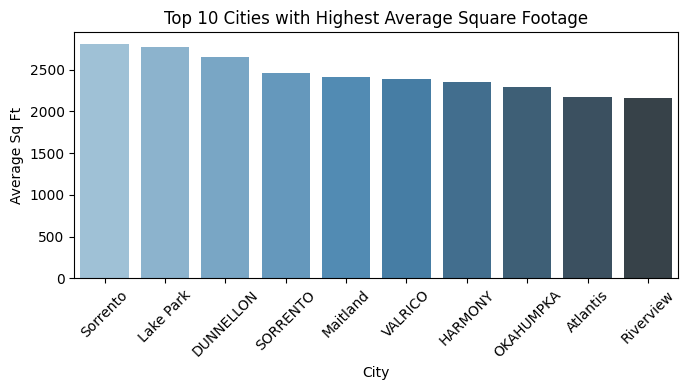

In [8]:
# Sort by 'Sq Ft' and select top 10 cities
top_10_cities = city_aggregation.sort_values(by="Sq Ft", ascending=False).head(10)

# Plot 1: Average Square Footage by Top 10 Cities
plt.figure(figsize=(7, 4))
sns.barplot(x="City", y="Sq Ft", data=top_10_cities, palette="Blues_d")
plt.title("Top 10 Cities with Highest Average Square Footage")
plt.ylabel("Average Sq Ft")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\faiza\AppData\Local\Temp\ipykernel_6564\2415566943.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="City", y="Price per Sq Ft", data=top_10_price_sq_ft, palette="Blues_d")


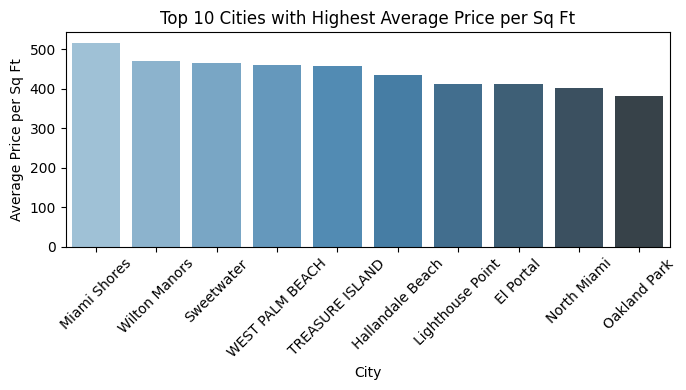

In [9]:
# Average Price per Sq Ft by Top 10 Cities
top_10_price_sq_ft = city_aggregation.sort_values(by="Price per Sq Ft", ascending=False).head(10)

plt.figure(figsize=(7, 4))
sns.barplot(x="City", y="Price per Sq Ft", data=top_10_price_sq_ft, palette="Blues_d")
plt.title("Top 10 Cities with Highest Average Price per Sq Ft")
plt.ylabel("Average Price per Sq Ft")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\faiza\AppData\Local\Temp\ipykernel_6564\950164570.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="City", y="Price per Sq Ft", data=top_10_price_sq_ft, palette="Blues_d")  # Adjust palette as desired


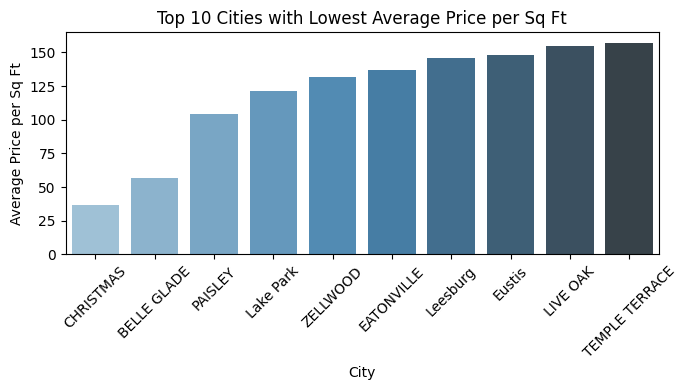

In [10]:
# Average Price per Sq Ft by Bottom 10 Cities
top_10_price_sq_ft = city_aggregation.sort_values(by="Price per Sq Ft").head(10)  # Sort by price (ascending) and take the first 10

# Invert the y-axis to show lowest prices at the top
plt.figure(figsize=(7, 4))
sns.barplot(x="City", y="Price per Sq Ft", data=top_10_price_sq_ft, palette="Blues_d")  # Adjust palette as desired
plt.title("Top 10 Cities with Lowest Average Price per Sq Ft")
plt.ylabel("Average Price per Sq Ft")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

C:\Users\faiza\AppData\Local\Temp\ipykernel_6564\4117069670.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="City", y="Lot Sq Ft", data=top_10_cities, palette="Blues_d")


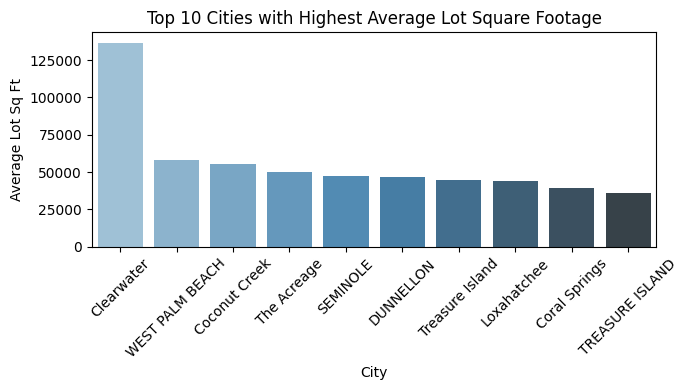

In [11]:
# Sort by 'Lot Sq Ft' and select top 20 cities
top_10_cities = city_aggregation.sort_values(by="Lot Sq Ft", ascending=False).head(10)


plt.figure(figsize=(7, 4))
sns.barplot(x="City", y="Lot Sq Ft", data=top_10_cities, palette="Blues_d")
plt.title("Top 10 Cities with Highest Average Lot Square Footage")
plt.ylabel("Average Lot Sq Ft")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\faiza\AppData\Local\Temp\ipykernel_6564\3710943220.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="City", y="Price", data=top_10_cities_price, palette="Blues_d")


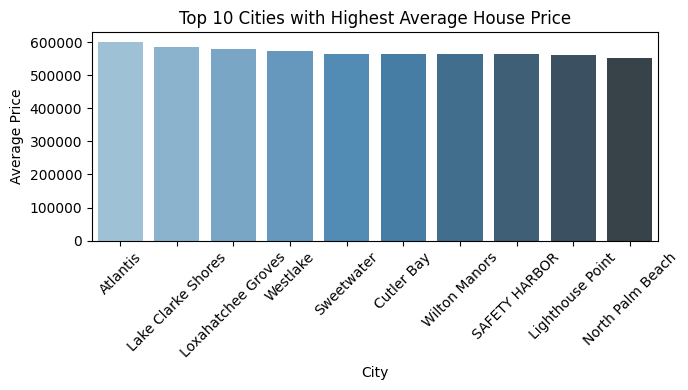

In [12]:
# Plot 3: Average Price by Top 10 Citie
top_10_cities_price = city_aggregation.sort_values(by="Price", ascending=False).head(10)

plt.figure(figsize=(7, 4))
sns.barplot(x="City", y="Price", data=top_10_cities_price, palette="Blues_d")
plt.title("Top 10 Cities with Highest Average House Price")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\faiza\AppData\Local\Temp\ipykernel_6564\2242262235.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="City", y="Price", data=top_10_cities_price, palette="Blues_d")


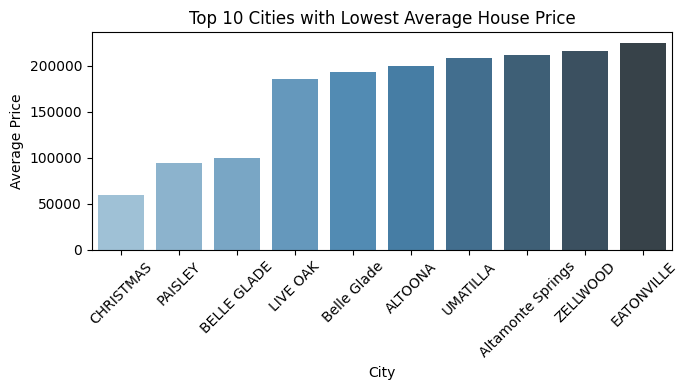

In [13]:
# Top 10 Cities with Lowest Average House Price
top_10_cities_price = city_aggregation.sort_values(by="Price", ascending=True).head(10)  # Sort by price (ascending) and take the first 10

plt.figure(figsize=(7, 4))
sns.barplot(x="City", y="Price", data=top_10_cities_price, palette="Blues_d")
plt.title("Top 10 Cities with Lowest Average House Price")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Optional: Invert y-axis to show lowest on top
# plt.gca().invert_yaxis()

C:\Users\faiza\AppData\Local\Temp\ipykernel_6564\1581745911.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="City", y="Beds", data=top_10_cities_beds, palette="Blues_d")


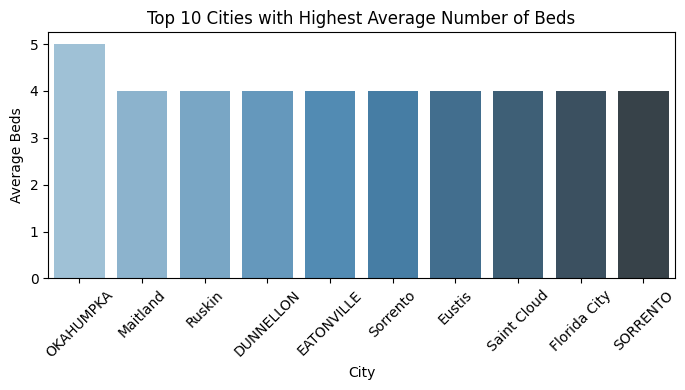

In [14]:
# Plot 4: Average Number of Beds by City
top_10_cities_beds = city_aggregation.sort_values(by="Beds", ascending=False).head(10)

plt.figure(figsize=(7, 4))
sns.barplot(x="City", y="Beds", data=top_10_cities_beds, palette="Blues_d")
plt.title("Top 10 Cities with Highest Average Number of Beds")
plt.ylabel("Average Beds")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\faiza\AppData\Local\Temp\ipykernel_6564\2316181693.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="City", y="Baths", data=top_10_cities_baths, palette="Blues_d")


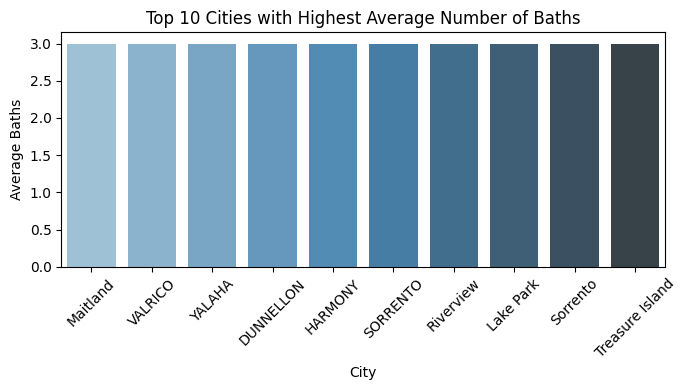

In [15]:
# Plot 5: Average Number of Baths by Top 10 Cities
top_10_cities_baths = city_aggregation.sort_values(by="Baths", ascending=False).head(10)

plt.figure(figsize=(7, 4))
sns.barplot(x="City", y="Baths", data=top_10_cities_baths, palette="Blues_d")
plt.title("Top 10 Cities with Highest Average Number of Baths")
plt.ylabel("Average Baths")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\faiza\AppData\Local\Temp\ipykernel_6564\2194106705.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="City", y="Garages", data=top_10_cities_garages, palette="Blues_d")


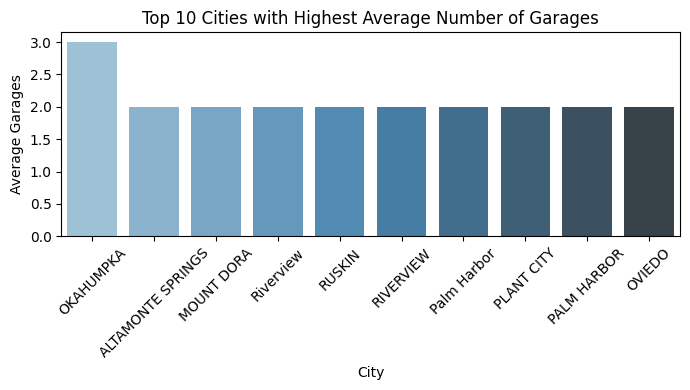

In [16]:
# Plot 6: Average Number of Garages by Top 10 Cities
top_10_cities_garages = city_aggregation.sort_values(by="Garages", ascending=False).head(10)

plt.figure(figsize=(7, 4))
sns.barplot(x="City", y="Garages", data=top_10_cities_garages, palette="Blues_d")
plt.title("Top 10 Cities with Highest Average Number of Garages")
plt.ylabel("Average Garages")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [33]:
# Separate features and target variable
X = df.drop(columns=['Price']) 
y = df['Price']

In [35]:
# One-hot encode categorical column 'City' 
X = pd.get_dummies(X, columns=['City'], drop_first=True)

In [36]:
# Adding Polynomial Features
poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
X_poly = poly.fit_transform(X)

In [37]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_poly, y, test_size=0.2, random_state=42)


In [38]:
# Baseline Models
# 1. Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_train_preds = lr_model.predict(X_train)
lr_test_preds = lr_model.predict(X_test)

#Error Metrics Evaluation
lr_mse = mean_squared_error(y_test, lr_test_preds)
lr_mae = mean_absolute_error(y_test, lr_test_preds)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_test, lr_test_preds)

print("\nLinear Regression Model Performance:")
print(f"  Mean Squared Error (MSE): {lr_mse}")
print(f"  Mean Absolute Error (MAE): {lr_mae}")
print(f"  Root Mean Squared Error (RMSE): {lr_rmse}")
print(f"  R-squared (R²): {lr_r2 * 100}\n")


Linear Regression Model Performance:
  Mean Squared Error (MSE): 54832335.01057367
  Mean Absolute Error (MAE): 1527.723316340556
  Root Mean Squared Error (RMSE): 7404.885887748283
  R-squared (R²): 99.57837843240259



In [39]:
# 2. Decision Tree Regressor
dt_model = DecisionTreeRegressor(random_state=40)
dt_model.fit(X_train, y_train)
dt_train_preds = dt_model.predict(X_train)
dt_test_preds = dt_model.predict(X_test)

#Error Metrics Evaluation
dt_mse = mean_squared_error(y_test, dt_test_preds)
dt_mae = mean_absolute_error(y_test, dt_test_preds)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test, dt_test_preds)

print("\nDecision Tree Regressor Model Performance:")
print(f"  Mean Squared Error (MSE): {dt_mse}")
print(f"  Mean Absolute Error (MAE): {dt_mae}")
print(f"  Root Mean Squared Error (RMSE): {dt_rmse}")
print(f"  R-squared (R²): {dt_r2 * 100}\n")


Decision Tree Regressor Model Performance:
  Mean Squared Error (MSE): 51104145.2832981
  Mean Absolute Error (MAE): 814.8350951374207
  Root Mean Squared Error (RMSE): 7148.716338147577
  R-squared (R²): 99.60704555366982



In [43]:
# 3. Artificial Neural Network (ANN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

ann_model = Sequential([
    Dense(512, input_dim=X_train_scaled.shape[1], activation='relu', kernel_regularizer=L2(0.05)),
    Dropout(0.2),
    Dense(256, activation='relu', kernel_regularizer=L2(0.01)),
    Dropout(0.2),
    Dense(128, activation='relu', kernel_regularizer=L2(0.01)),
    Dropout(0.2),
    Dense(1)
])

ann_model.compile(optimizer='adam', loss='mean_squared_error')
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = ann_model.fit(X_train_scaled, y_train, epochs=150, batch_size=64, validation_split=0.2, callbacks=[early_stopping])

ann_train_preds = ann_model.predict(X_train_scaled).flatten()
ann_test_preds = ann_model.predict(X_test_scaled).flatten()

#Error Metrics Evaluation
ann_mse = mean_squared_error(y_test, ann_test_preds)
ann_mae = mean_absolute_error(y_test, ann_test_preds)
ann_rmse = np.sqrt(ann_mse)
ann_r2 = r2_score(y_test, ann_test_preds)

print("\nArtificial Neural Network (ANN) Model Performance:")
print(f"  Mean Squared Error (MSE): {ann_mse}")
print(f"  Mean Absolute Error (MAE): {ann_mae}")
print(f"  Root Mean Squared Error (RMSE): {ann_rmse}")
print(f"  R-squared (R²): {ann_r2 * 100}\n")

c:\Users\faiza\OneDrive\Desktop\ML nd Streamlit\Research\venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 12s 335ms/step - loss: 160552747008.0000 - val_loss: 160249708544.0000
Epoch 2/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 294ms/step - loss: 159212240896.0000 - val_loss: 156527329280.0000
Epoch 3/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 305ms/step - loss: 148155056128.0000 - val_loss: 134406701056.0000
Epoch 4/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 305ms/step - loss: 104629362688.0000 - val_loss: 73488965632.0000
Epoch 5/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 299ms/step - loss: 38169370624.0000 - val_loss: 28456480768.0000
Epoch 6/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 279ms/step - loss: 18175242240.0000 - val_loss: 19946813440.0000
Epoch 7/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 284ms/step - loss: 11773715456.0000 - val_loss: 15982897152.0000
Epoch 8/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 290ms/step - loss: 8958724096.0000 - val_loss: 13856396288.0000
Epoch 9/150
24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 284ms/step - loss: 7418207232.0000 - val_loss: 12672727040.0000
Epoch 10/150
24/24 ━━━━━━━━━━━━

In [44]:
# Stacking (Hybrid Model)
stack_train_features = np.column_stack((lr_train_preds, dt_train_preds, ann_train_preds))
stack_test_features = np.column_stack((lr_test_preds, dt_test_preds, ann_test_preds))

stacking_model = Ridge(random_state=42)
stacking_model.fit(stack_train_features, y_train)

hybrid_train_preds = stacking_model.predict(stack_train_features)
hybrid_test_preds = stacking_model.predict(stack_test_features)

#Error Metrics Evaluation
hybrid_mse = mean_squared_error(y_test, hybrid_test_preds)
hybrid_mae = mean_absolute_error(y_test, hybrid_test_preds)
hybrid_rmse = np.sqrt(hybrid_mse)
hybrid_r2 = r2_score(y_test, hybrid_test_preds)

print("\nHybrid Model Performance (Stacking Approach):")
print(f"  Mean Squared Error (MSE): {hybrid_mse}")
print(f"  Mean Absolute Error (MAE): {hybrid_mae}")
print(f"  Root Mean Squared Error (RMSE): {hybrid_rmse}")
print(f"  R-squared (R²): {hybrid_r2 * 100}")


Hybrid Model Performance (Stacking Approach):
  Mean Squared Error (MSE): 51104145.283247955
  Mean Absolute Error (MAE): 814.8350951384601
  Root Mean Squared Error (RMSE): 7148.71633814407
  R-squared (R²): 99.60704555367022


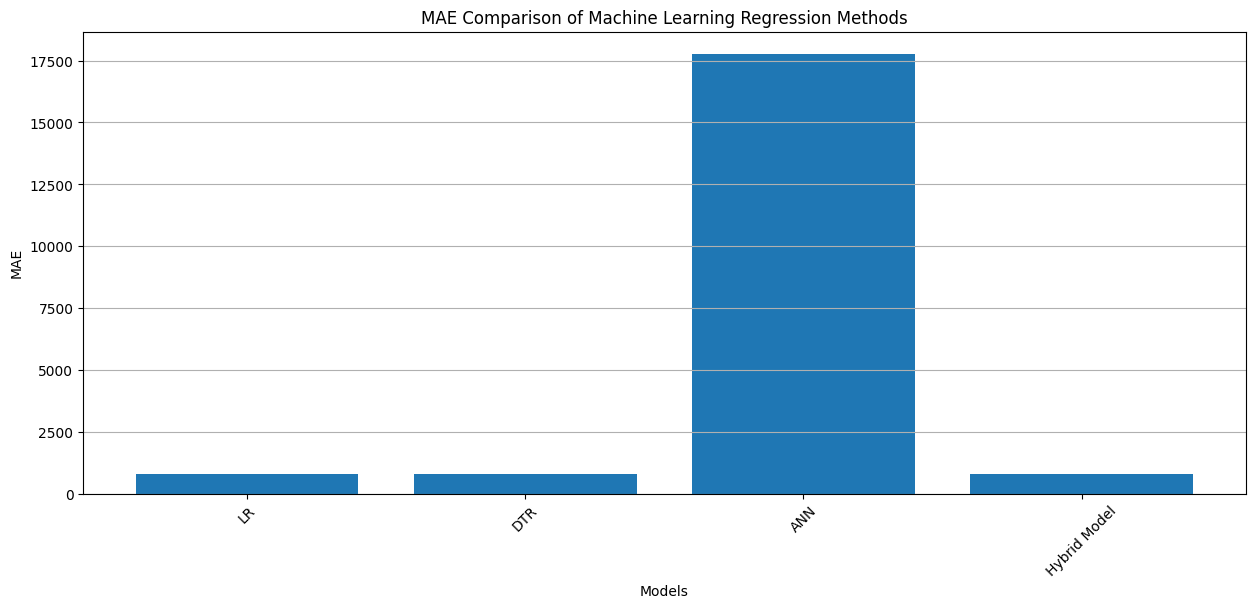

In [25]:
model_names = ['LR', 'DTR', 'ANN', 'Hybrid Model']
mae_values = [798.29, 798.29, 17781.05, 798.29 ]

# Create a bar chart
plt.figure(figsize=(15, 6))
plt.bar(model_names, mae_values)

# Customize the plot
plt.title('MAE Comparison of Machine Learning Regression Methods')
plt.xlabel('Models')
plt.ylabel('MAE')
plt.xticks(rotation=45)  
plt.grid(axis='y')

# Show the plot
plt.show()

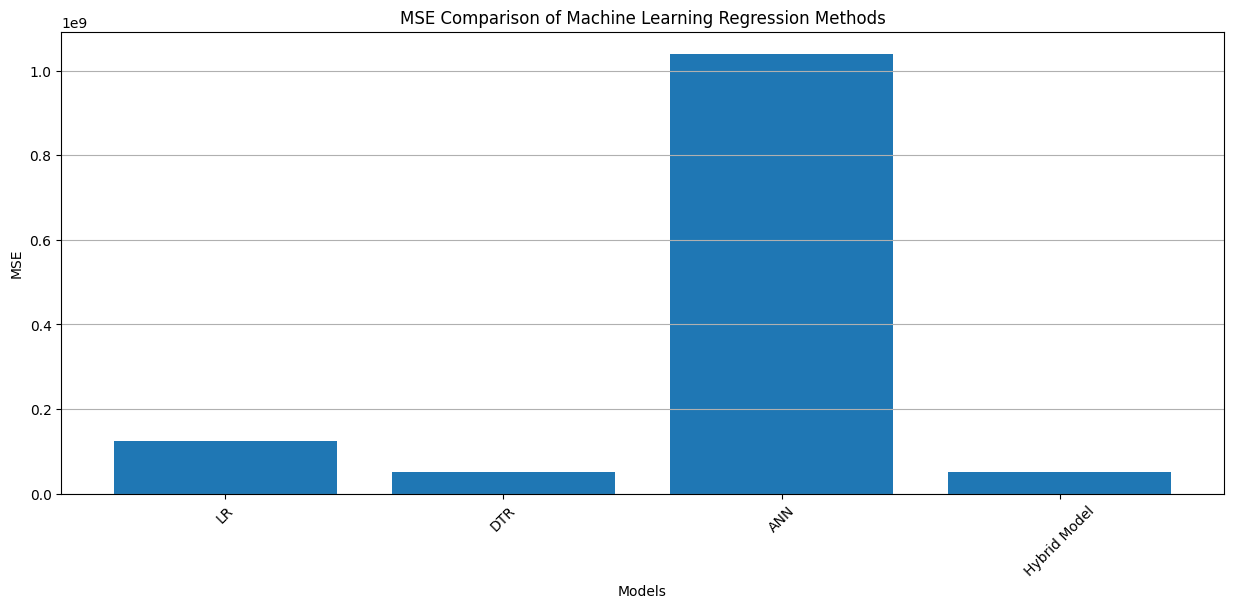

In [26]:
model_names = ['LR', 'DTR', 'ANN', 'Hybrid Model']
mse_values = [124744084.95, 51038731.41, 1040079425.18, 51038731.41 ]

# Create a bar chart
plt.figure(figsize=(15, 6))
plt.bar(model_names, mse_values)

# Customize the plot
plt.title('MSE Comparison of Machine Learning Regression Methods')
plt.xlabel('Models')
plt.ylabel('MSE')
plt.xticks(rotation=45)  
plt.grid(axis='y')

# Show the plot
plt.show()

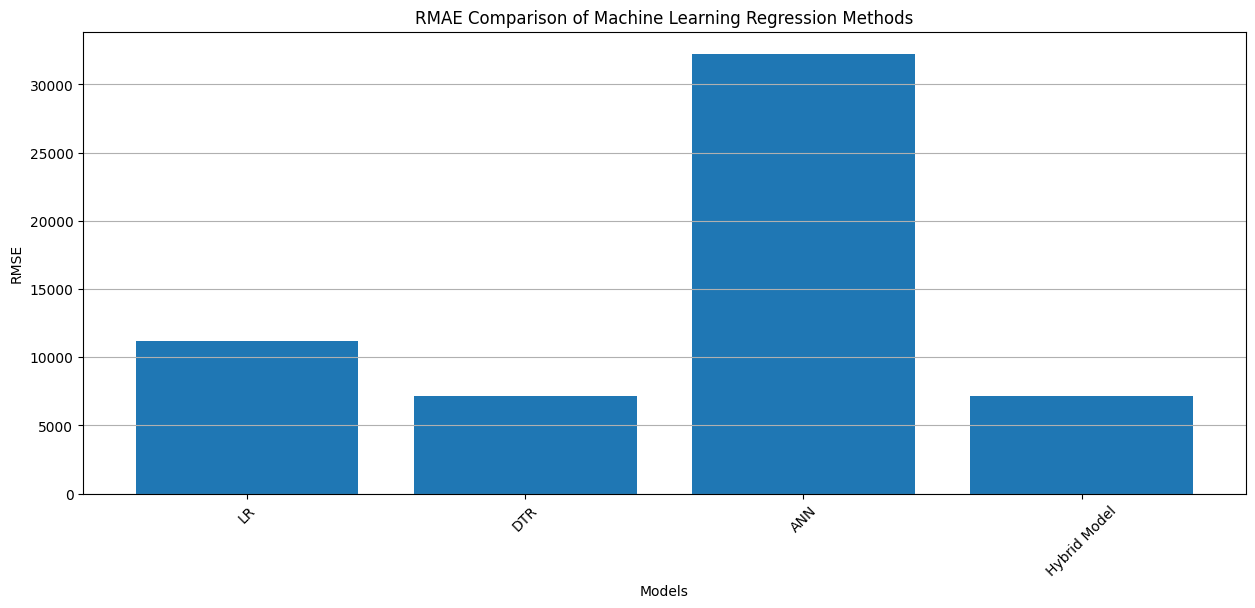

In [27]:
model_names = ['LR', 'DTR', 'ANN', 'Hybrid Model']
rmse_values = [11168.88, 7144.13, 32250.26, 7144.13 ]

# Create a bar chart
plt.figure(figsize=(15, 6))
plt.bar(model_names, rmse_values)

# Customize the plot
plt.title('RMAE Comparison of Machine Learning Regression Methods')
plt.xlabel('Models')
plt.ylabel('RMSE')
plt.xticks(rotation=45)  
plt.grid(axis='y')

# Show the plot
plt.show()

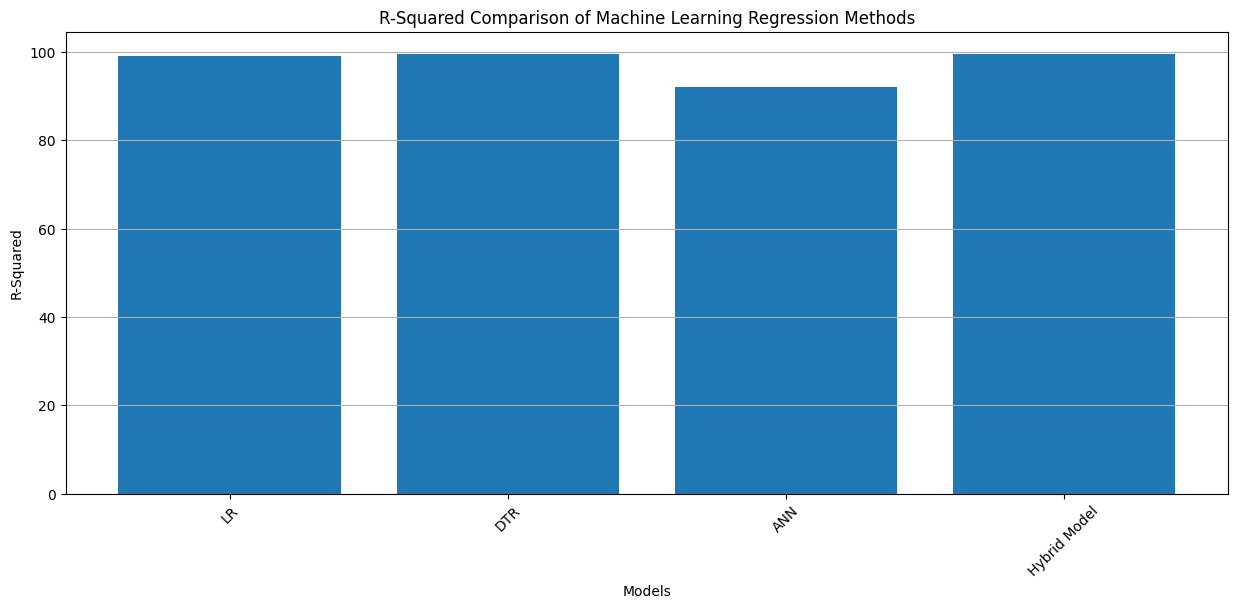

In [28]:
model_names = ['LR', 'DTR', 'ANN', 'Hybrid Model']
r_squared_values = [99.04, 99.60, 92.00, 99.60 ]

# Create a bar chart
plt.figure(figsize=(15, 6))
plt.bar(model_names, r_squared_values)

# Customize the plot
plt.title('R-Squared Comparison of Machine Learning Regression Methods')
plt.xlabel('Models')
plt.ylabel('R-Squared')
plt.xticks(rotation=45)
plt.grid(axis='y')

# Show the plot
plt.show()

In [51]:
joblib.dump(stacking_model, "hybrid_ridge_model.joblib")
print("Hybrid Ridge meta-model saved as hybrid_ridge_model.joblib")
 
# ----------------------------------------------------------- NEW: save for app
OUT_DIR = "artifacts"
os.makedirs(OUT_DIR, exist_ok=True)
 
joblib.dump(poly, f"{OUT_DIR}/poly.joblib")
joblib.dump(scaler, f"{OUT_DIR}/scaler.joblib")
joblib.dump(lr_model, f"{OUT_DIR}/lr.joblib")
joblib.dump(dt_model, f"{OUT_DIR}/dt.joblib")
joblib.dump(stacking_model, f"{OUT_DIR}/stacking.joblib")
ann_model.save(f"{OUT_DIR}/ann.keras")
city_aggregation.to_csv(f"{OUT_DIR}/city_aggregation.csv", index=False)
 
feature_columns = X.columns.tolist()
defaults = {c: float(X[c].mean()) for c in feature_columns if not c.startswith("City_")}
metrics = {
    "Linear Regression": {"MAE": lr_mae, "MSE": lr_mse, "RMSE": lr_rmse, "R2": lr_r2 * 100},
    "Decision Tree": {"MAE": dt_mae, "MSE": dt_mse, "RMSE": dt_rmse, "R2": dt_r2 * 100},
    "ANN": {"MAE": ann_mae, "MSE": ann_mse, "RMSE": ann_rmse, "R2": ann_r2 * 100},
    "Hybrid (Stacking)": {"MAE": hybrid_mae, "MSE": hybrid_mse, "RMSE": hybrid_rmse, "R2": hybrid_r2 * 100},
}
with open(f"{OUT_DIR}/meta.json", "w") as f:
    json.dump({"feature_columns": feature_columns,
               "defaults": defaults,
               "metrics": {k: {m: float(v) for m, v in d.items()} for k, d in metrics.items()}},
              f, indent=2)
 
pd.DataFrame({
    "Actual": y_test.values,
    "Hybrid (Stacking)": hybrid_test_preds,
}).sample(n=min(1500, len(y_test)), random_state=1).to_csv(f"{OUT_DIR}/test_predictions.csv", index=False)
 
print(f"\nApp artifacts saved in ./{OUT_DIR}")

Hybrid Ridge meta-model saved as hybrid_ridge_model.joblib

App artifacts saved in ./artifacts
